<a href="https://colab.research.google.com/github/Aylinbaki/AI-Masters-Preparation/blob/main/02_pytorch_loop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tensor: A structure used to store numerical data

Loss: A value that measures how much a prediction differs from the actual result

Gradient: A derivative that indicates how the loss changes when a parameter is altered

Backpropagation: The process of calculating gradients in reverse using the chain rule

Optimizer: An algorithm that updates parameters using the calculated gradients

Autograd is PyTorch's automatic differentiation system. Setting `requires_grad=True` enables gradient tracking. `loss.backward()` computes the gradients, while `optimizer.step()` updates the parameters. This allows the model to learn by reducing the loss value.

In [1]:

import torch

# A tensor consisting of three rows and one column
x = torch.tensor([[1.0], [2.0], [3.0]])

print("Tensor:")
print(x)

print("Shape:", x.shape)
print("Data type:", x.dtype)

# y = 2x + 1
y = 2 * x + 1
print("Sonuç:", y)


Tensor:
tensor([[1.],
        [2.],
        [3.]])
Shape: torch.Size([3, 1])
Data type: torch.float32
Sonuç: tensor([[3.],
        [5.],
        [7.]])


In [2]:
import torch

# A learnable variable
w = torch.tensor(0.5, requires_grad=True)

# A simple loss function
loss = (w - 2) ** 2

# Gradient calculation
loss.backward()

print("Loss:", loss.item())
print("Gradient:", w.grad.item())

Loss: 2.25
Gradient: -3.0


loss -> (0,5-2)^2

gradient(türev aldık) -> 2(w-2)= 2x(-1,5)= -3

In [4]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# 1. Training data: y = 2x + 1
x_train = torch.linspace(-2, 2, 80).reshape(-1, 1)
y_train = 2 * x_train + 1

#2. Model
model = nn.Linear(1, 1)

#3. Loss and optimizer
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(
    model.parameters(), lr=0.1
)

losses = []

# 4. Training cycle
for epoch in range(100):
    # Forward pass: make a prediction
    prediction = model(x_train)

    # Calculate error
    loss = loss_fn(prediction, y_train)

    # Clear old gradients
    optimizer.zero_grad()

    # Calculate new gradients
    loss.backward()

    # Update parameters
    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) in [1, 10, 50, 100]:
        print(f"Epoch {epoch+1}: Loss = {loss.item():.6f}")

print("Learned weight:", model.weight.item())
print("Learned bias:", model.bias.item())

Epoch 1: Loss = 2.115573
Epoch 10: Loss = 0.007167
Epoch 50: Loss = 0.000000
Epoch 100: Loss = 0.000000
Learned weight: 1.9999998807907104
Learned bias: 0.9999998807907104


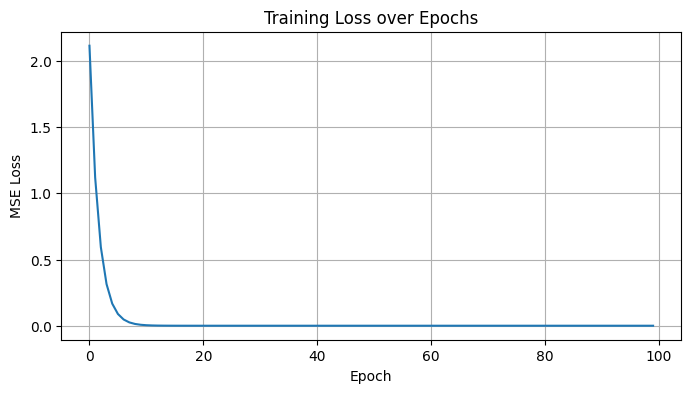

Prediction for x = 1.5: 3.999999523162842
Actual value: 4.0


In [6]:

plt.figure(figsize=(8, 4))

plt.plot(losses)
plt.title("Training Loss over Epochs")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.grid(True)
plt.show()

# Prediction using the learned model
with torch.no_grad():
    result = model(torch.tensor([[1.5]]))

print("Prediction for x = 1.5:", result.item())
print("Actual value:", 2 * 1.5 + 1)